# Chapter 15 · Convergence of random variables and the laws of large numbers: interactive demos

Companion to Chapter 15 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/15-laws-large-numbers.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.convergence import (LAWS, bernoulli_mean_tail, chebyshev_bound, chebyshev_sample_size,
                                   deviation_probability, first_n_below, last_n_above, mode_quantities,
                                   sample_means, spike, tail_sup_deviation, typewriter, typewriter_index,
                                   typewriter_interval)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. The two counterexamples

On $\Omega=[0,1]$ with Lebesgue measure, the notes compare two sequences that both converge to $0$ in probability.

* **Typewriter** (Example 15.6): $X_n=\mathbf 1_{A_n}$, where the intervals $A_n=[\frac{j-1}k,\frac jk]$ sweep $[0,1]$ block
  after block, with width $\frac1k\to0$.
* **Spike** (Example 15.7): $X_n=2^n\mathbf 1_{(0,\frac1n)}$.

Left: the path $m\mapsto X_m(\omega)$ at a fixed $\omega$, for $m\le n$ (for the spike, the indicator $X_m(\omega)\ne0$). The typewriter
path returns to $1$ in every block, so it converges at no $\omega$; the spike path is eventually $0$. Right: the three numbers that
decide the three modes of convergence to $0$, computed exactly: $\mathbb P(|X_m|>\varepsilon)$ (in probability),
$d(X_m,0)=\mathbb E\big[\frac{|X_m|}{1+|X_m|}\big]$ (the same mode, Proposition 15.3) and $\mathbb E|X_m|^p$ (in $L^p$).

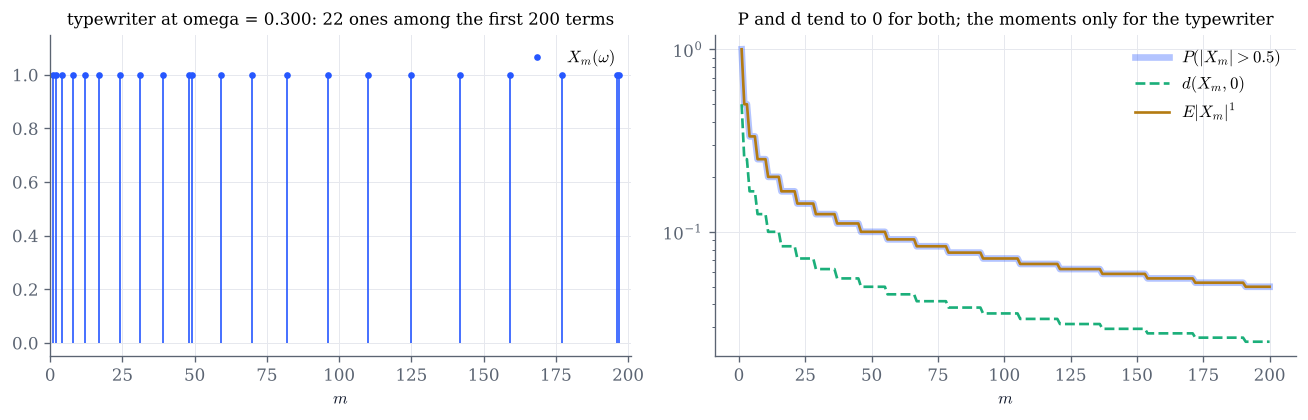

n = 200  (block k = 20, j = 10, A_n = [0.4500, 0.5000])
  P(|X_n| > 0.5) = 0.05,  d(X_n, 0) = 0.025,  log10 E|X_n|^1 = -1.301


In [3]:
def counterexample_demo(kind="typewriter", n=200, omega=0.3, p=1.0, eps=0.5):
    m = np.arange(1, n + 1)
    if kind == "typewriter":
        path = typewriter(m, omega)
        lab = r"$X_m(\omega)$"
    else:
        path = (spike(m, omega) > 0).astype(float)
        lab = r"$\mathbf{1}\{X_m(\omega)\neq0\}$"
    q = mode_quantities(kind, m, p=p, eps=eps)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    a1.vlines(m, 0, path, color=COBALT, lw=1.0)
    a1.plot(m[path > 0], path[path > 0], "o", color=COBALT, ms=3, label=lab)
    a1.set(xlabel="$m$", ylim=(-0.05, 1.15), xlim=(0, n + 1),
           title=f"{kind} at omega = {omega:.3f}: {int(path.sum())} ones among the first {n} terms")
    a1.legend(loc="upper right")
    a2.semilogy(m, q["prob"], color=COBALT, lw=4, alpha=0.35, label=rf"$P(|X_m|>{eps:g})$")
    a2.semilogy(m, q["metric"], color=GREEN, ls="--", label=r"$d(X_m,0)$")
    with np.errstate(over="ignore"):
        mom = np.where(q["log2_moment"] < 1000, np.exp2(q["log2_moment"]), np.nan)
    a2.semilogy(m, mom, color=GOLD, label=rf"$E|X_m|^{{{p:g}}}$")
    a2.set(xlabel="$m$", title="P and d tend to 0 for both; the moments only for the typewriter")
    # for the typewriter, P(|X_m| > eps) = E|X_m|^p = 1/k when eps < 1: the two curves coincide
    a2.legend(loc="best")
    fig.tight_layout()
    plt.show()
    k, j = typewriter_index(n) if kind == "typewriter" else (None, None)
    where = f"  (block k = {k}, j = {j}, A_n = [{(j - 1) / k:.4f}, {j / k:.4f}])" if k is not None else ""
    print(f"n = {n}{where}")
    print(f"  P(|X_n| > {eps:g}) = {float(q['prob'][-1]):.4g},  d(X_n, 0) = {float(q['metric'][-1]):.4g},  "
          f"log10 E|X_n|^{p:g} = {float(q['log2_moment'][-1]) * math.log10(2):.4g}")

counterexample_demo()

In [4]:
# Explore: move omega and n. For the typewriter, every omega is hit once (or twice) per block;
# for the spike, the path is 0 for good from m > 1/omega on. Compare p = 1 and p = 2.
interact(counterexample_demo,
         kind=Dropdown(options=["typewriter", "spike"], value="typewriter", description="sequence"),
         n=IntSlider(value=200, min=10, max=2000, step=10, continuous_update=False, description="n"),
         omega=FloatSlider(value=0.3, min=0.0, max=1.0, step=0.001, readout_format=".3f",
                           continuous_update=False, description="omega"),
         p=FloatSlider(value=1.0, min=1.0, max=4.0, step=0.5, continuous_update=False, description="p"),
         eps=FloatSlider(value=0.5, min=0.05, max=1.5, step=0.05, continuous_update=False, description="eps"));

## 2. Sample means: the weak and the strong law

For i.i.d. variables in $L^2$ with mean $\mu$ and variance $\sigma^2$, Chebyshev's inequality gives
$\mathbb P(|\bar X_n-\mu|>\varepsilon)\le\frac{\sigma^2}{n\varepsilon^2}$ (weak law, Theorem 15.12), and the strong law (Theorem 15.13)
says that almost every path eventually stays within $\varepsilon$ of $\mu$: $\mathbb P\big(\sup_{m\ge n}|\bar X_m-\mu|>\varepsilon\big)\to0$.
Left: simulated paths of $\bar X_n$ and the band $\mu\pm\varepsilon$. Right: the estimated probability that $\bar X_n$ is outside the band
(blue), the estimated probability that the path leaves the band at some time between $n$ and the horizon (gold), and Chebyshev's
bound (green). For the Bernoulli law the exact probability is drawn too. The Cauchy law is not in $L^1$: there is no mean, no
bound, and no settling (Exercise 15.6); its band is drawn around its centre $0$.

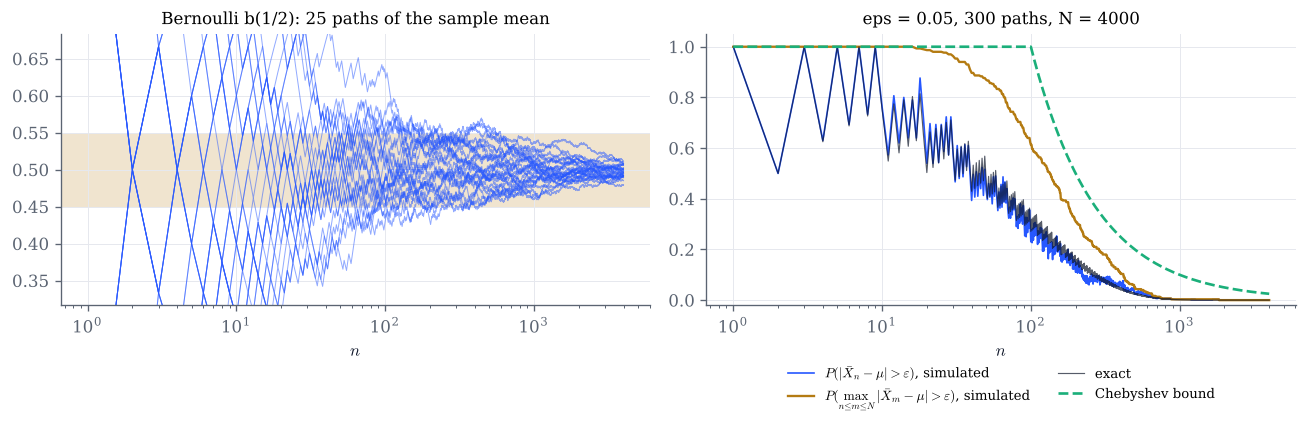

In [5]:
def lln_demo(law="bernoulli", N=4000, eps=0.05, paths=300, seed=2026):
    L = LAWS[law]
    mu = 0.0 if math.isnan(L.mean) else L.mean
    m = sample_means(law, N, paths, seed=seed)
    n = np.arange(1, N + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    for r in range(min(paths, 25)):
        a1.plot(n, m[r], color=COBALT, lw=0.6, alpha=0.5)
    a1.axhspan(mu - eps, mu + eps, color=GOLD, alpha=0.2, lw=0)
    a1.set(xscale="log", xlabel="$n$", title=f"{L.name}: 25 paths of the sample mean")
    if law == "cauchy":
        a1.set_ylim(-5, 5)
    else:
        lo, hi = np.quantile(m[:25], [0.001, 0.999])
        a1.set_ylim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
    dev = deviation_probability(m, mu, eps)
    sup = np.mean(tail_sup_deviation(m, mu) > eps + 1e-9, axis=0)
    a2.plot(n, dev, color=COBALT, lw=1.0, label=r"$P(|\bar X_n-\mu|>\varepsilon)$, simulated")
    a2.plot(n, sup, color=GOLD, lw=1.4, label=r"$P(\max_{n\leq m\leq N}|\bar X_m-\mu|>\varepsilon)$, simulated")
    if law == "bernoulli":
        a2.plot(n, bernoulli_mean_tail(n, 0.5, eps), color=INK, lw=0.7, alpha=0.7, label="exact")
    if not math.isnan(L.var):
        a2.plot(n, chebyshev_bound(L.var, n, eps), color=GREEN, ls="--", label="Chebyshev bound")
    a2.set(xscale="log", ylim=(-0.02, 1.05), xlabel="$n$", title=f"eps = {eps:g}, {paths} paths, N = {N}")
    a2.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
    fig.tight_layout()
    plt.show()

lln_demo()

In [6]:
# Explore: change the law and eps. For the Cauchy law nothing settles, whatever N; for the others the gold
# curve (strong law) lies above the blue one (weak law) but also tends to 0.
interact(lln_demo,
         law=Dropdown(options=list(LAWS), value="bernoulli", description="law"),
         N=IntSlider(value=4000, min=500, max=10000, step=500, continuous_update=False, description="N"),
         eps=FloatSlider(value=0.05, min=0.01, max=0.5, step=0.01, continuous_update=False, description="eps"),
         paths=IntSlider(value=300, min=50, max=1000, step=50, continuous_update=False, description="paths"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 3. How large a sample? Chebyshev against the exact answer

A poll estimates $p$ by the proportion $\bar X_n$ in a sample of size $n$. Chebyshev's bound
$\frac{p(1-p)}{n\varepsilon^2}\le\delta$ gives a sample size that is always enough; the exact binomial probability
$\mathbb P(|\bar X_n-p|>\varepsilon)$ shows how much smaller a sample suffices (Exercise 15.5). The exact curve is not monotone:
$S_n$ is an integer, and the event $\{|S_n-np|>n\varepsilon\}$ gains a whole value of $S_n$ each time $n\varepsilon$ crosses an
integer. The dotted lines mark the first $n$ with probability at most $\delta$, and the $n$ from which it stays there.

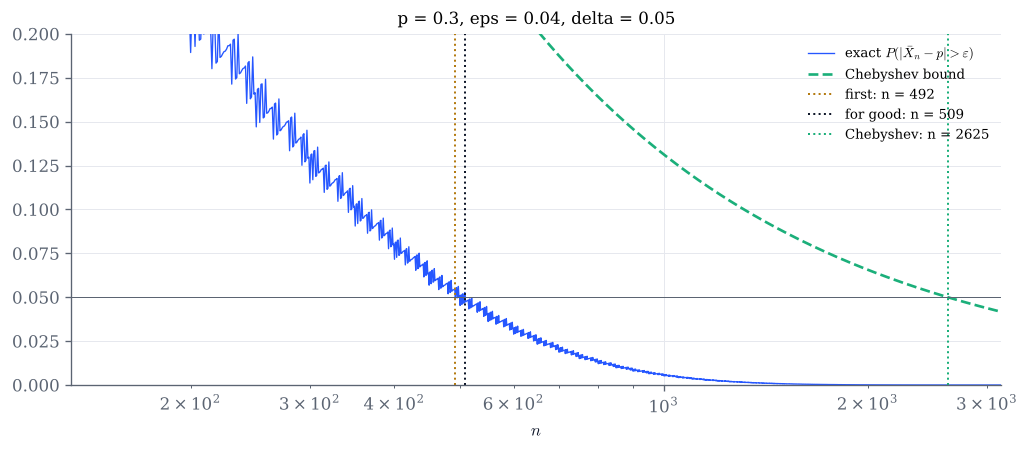

Chebyshev: n >= 2625;  exact: first n = 492, below delta for good from n = 509


In [7]:
def sample_size_demo(p=0.3, eps=0.04, delta=0.05):
    var = p * (1 - p)
    n_cheb = chebyshev_sample_size(var, eps, delta)
    n_max = max(50, int(1.2 * n_cheb))
    n = np.arange(1, n_max + 1)
    tail = bernoulli_mean_tail(n, p, eps)
    f = lambda k: bernoulli_mean_tail(k, p, eps)
    first, stable = first_n_below(f, delta, n_max), last_n_above(f, delta, n_max) + 1
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(n, tail, color=COBALT, lw=0.8, label=r"exact $P(|\bar X_n-p|>\varepsilon)$")
    ax.plot(n, chebyshev_bound(var, n, eps), color=GREEN, ls="--", label="Chebyshev bound")
    ax.axhline(delta, color=GREY, lw=0.6)
    for x, c, t in ((first, GOLD, "first"), (stable, INK, "for good"), (n_cheb, GREEN, "Chebyshev")):
        if x:
            ax.axvline(x, color=c, ls=":", lw=1.2, label=f"{t}: n = {x}")
    left = first_n_below(f, min(1.0, 4 * delta), n_max) or 1
    ax.set(xscale="log", xlim=(max(1, left / 1.5), n_max), ylim=(0, min(1.0, 4 * delta)), xlabel="$n$",
           title=f"p = {p:g}, eps = {eps:g}, delta = {delta:g}")
    ax.legend(fontsize=8, loc="upper right")
    plt.show()
    print(f"Chebyshev: n >= {n_cheb};  exact: first n = {first}, below delta for good from n = {stable}")

sample_size_demo()

In [8]:
# Explore: smaller delta makes Chebyshev's sample size grow like 1/delta; the exact one grows much more slowly.
interact(sample_size_demo,
         p=FloatSlider(value=0.3, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p"),
         eps=FloatSlider(value=0.04, min=0.02, max=0.2, step=0.01, continuous_update=False, description="eps"),
         delta=FloatSlider(value=0.05, min=0.01, max=0.2, step=0.01, continuous_update=False, description="delta"));

## Things to try

- In section 1, run `counterexample_demo(omega=1/3, n=60)` in a new cell (the slider cannot reach $\frac13$) and count the ones in the blocks $k=3,6,9$: why two? Then try $\omega=0$ for the spike.
- In section 1, the typewriter with $p=4$: does $\mathbb E|X_n|^p$ depend on $p$? Why not?
- In section 2, take the uniform law and $\varepsilon=0.01$: how does Chebyshev compare with the simulation as $n$ grows?
- In section 2, take the Cauchy law with $N=10000$: does the fraction of paths outside the band move at all?
- In section 3, find the sample size Chebyshev asks for with $p=0.5$, $\varepsilon=0.05$, $\delta=0.01$, and compare with the exact one.